# CP tensor fitting: final paper experiment

This notebook contains the authoritative numerical definitions for the 30 x 30 x 30,
rank-5 experiment. The command-line runner imports these definitions without running
notebook experiments or plots. See [README.md](README.md) for the complete protocol.

Run Jupyter from this directory. **Restart Kernel and Run All** is safe by default:
`RUN_EXPERIMENTS = False` leaves the solvers idle and displays the archived final figure.
Set it to `True` explicitly to generate the complete filtered and unfiltered experiment.
The run takes substantially longer than loading the saved figure.

The final figure uses ten paired initializations, 2% fixed approximation perturbation,
5% fresh Gaussian query noise, and the original fixed replacement corruption.
The filtered methods use q=0.85; the two unfiltered controls use q=1.


In [1]:
import json
import hashlib
import time
from datetime import datetime
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from src.utils.methods import noisy_methods_optimized

## 1. Settings

The canonical settings below specify the filtered experiment. The shared runner
uses the same settings with q=1 for the two unfiltered controls. The paper uses
120/120/60 outer sweeps for exact/query-noise/approximate fitting, while the figure
shows 60/30/30. Initializations and all random inputs are paired across methods.
The 2% fixed perturbation is distinct from the 5% fresh query-noise scale.


In [ ]:
RUN_EXPERIMENTS = False  # Set True explicitly to run all solvers.

settings = {
    "shape": [30, 30, 30],
    "rank": 5,
    "trials": 10,
    "paired_initializations": True,    # Records the trial protocol in saved results.
    "batch_sizes": [1, 5, 10, 50],       # 1 is QRK; AQRK (all) is also included.
    "q": 0.85,
    "alpha": 1.0,
    "outer_sweeps": {"exact": 120, "approximate": 60, "query_noise": 120},
    "adaptive_stopping": True,
    "inner_iterations": 500,           # Exact budget if adaptive_stopping is False.
    "min_inner_iterations": 40,
    "window": 20,
    "plateau_patience": 2,             # Consecutive unsuccessful progress checks.
    "plateau_tolerance": 0.001,         # 0.1% relative improvement.
    "residual_tolerance": 1e-12,
    "dense_noise_relative_level": 0.02,
    "corruption_fraction": 0.10,
    "replacement_scale": 2.0,
    "replacement_quantile": 0.90,
    "als_ridge": 1e-8,
    "true_seed": 0,
    "initialization_seed": 1,          # Trials use 1, 2, ..., 10.
    "dense_noise_seed": 7,
    "corruption_seed": 42,
    "query_noise_relative_std": 0.05,
    "first_query_seed": 70124,         # Separate from row-sampling seeds.
    "als_query_noise_seed": 70042,      # One fixed noisy tensor for ALS.
    "experiment_version": "cp_unit_rows_query_noise_v3",
    "quantile_method": "linear",
    "inner_row_normalization": "matrix_and_rhs_once_per_mode",
    "filtering_residuals": "row_normalized",
    "stopping_residuals": "row_normalized",
    "quantile_ties": "retain",
    "first_sampling_seed": 124,         # Trials use 124, 126, 128, ...
}

assert settings["trials"] >= 1 and settings["inner_iterations"] >= 1
assert 0 < settings["q"] <= 1 and 0 <= settings["corruption_fraction"] < 1
assert min(settings["batch_sizes"]) >= 1
assert len(set(settings["batch_sizes"])) == len(settings["batch_sizes"])
if settings["adaptive_stopping"]:
    assert 2 * settings["window"] <= settings["min_inner_iterations"] <= settings["inner_iterations"]

assert settings["query_noise_relative_std"] >= 0
assert isinstance(settings["plateau_patience"], int) and settings["plateau_patience"] >= 1

## 2. CP operations

Column normalization returns the component weights. Those weights are absorbed
into the first factor before the next sweep, preserving the warm start.

This CP column normalisation is distinct from row normalisation of an inner
linear system. `normalize_inner_systems` scales the shared design and every
RHS once per mode update; zero design rows are omitted for all quantile methods.
ALS retains its ordinary, unscaled least-squares subproblem and ridge.

In [3]:
def cp_tensor(factors, weights=None):
    A, B, C = factors
    if weights is None:
        return np.einsum("ir,jr,kr->ijk", A, B, C)
    return np.einsum("r,ir,jr,kr->ijk", weights, A, B, C)


def unfold(tensor, mode):
    return np.moveaxis(tensor, mode, 0).reshape(tensor.shape[mode], -1)


def khatri_rao(left, right):
    return np.einsum("ir,jr->ijr", left, right).reshape(-1, left.shape[1])


def normalize_factors(factors):
    normalized = []
    weights = np.ones(factors[0].shape[1])
    for factor in factors:
        norms = np.linalg.norm(factor, axis=0)
        norms = np.where(norms > 0, norms, 1.0)
        normalized.append(factor / norms)
        weights *= norms
    return normalized, weights


def relative_error(target, estimate):
    return float(np.linalg.norm((target - estimate).ravel()) /
                 max(float(np.linalg.norm(target.ravel())), 1e-15))



def normalize_inner_systems(matrix, right_hand_sides):
    """Unit rows and matching RHS scaling; RHS vectors are stored as rows."""
    norms = np.linalg.norm(matrix, axis=1)
    good = np.flatnonzero(norms > 0)
    inverse_norms = 1.0 / norms[good]
    unit_matrix = matrix[good] * inverse_norms[:, None]
    scaled_rhs = right_hand_sides[:, good] * inverse_norms[None, :]
    return unit_matrix, scaled_rhs, inverse_norms

## 3. Filtered or unfiltered updates on unit-row systems

Filtering, updates and stopping all use the normalized equations. Sampled rows
are drawn with replacement. Fresh query noise is independent for every occurrence,
including duplicate rows. All-row updates reuse screening observations. The q=1
setting retains all rows. A shared partition gives the interpolated quantile and
trimmed RMS; deterministic scalar products are reused within each update.
The stopping rule uses two consecutive insufficient-progress checks; see README.


In [4]:
# Stop codes: 0 fixed budget, 1 cap, 2 plateau, 3 residual floor, 4 no rows.
inner_columns = ["sweep", "mode", "row", "updates", "residual_scans",
                 "row_corrections", "stop_code", "initial_trimmed_rms",
                 "final_trimmed_rms", "selection_queries", "update_queries",
                 "diagnostic_queries"]

def filtered_kaczmarz(M, b, x0, batch_size, settings, rng, *,
                      query_std=None, selection_rng=None, update_rng=None,
                      requery=False):
    return noisy_methods_optimized.filtered_kaczmarz(
        M, b, x0, batch_size, settings, rng,
        query_width=query_std, noise_distribution="gaussian",
        selection_rng=selection_rng, update_rng=update_rng, requery=requery)

## 4. Alternating CP sweeps

Each factor update precomputes the common unit-row design and all scaled RHS
vectors, then solves one inner system per factor row. QRK and every AQRK
variant use the same preprocessing. CP component weights are carried between
sweeps exactly as in the original notebook.

ALS solves the ordinary ridge-regularised subproblem, with ridge $10^{-8}$.
In case 3 its input is one fixed noisy tensor saved with the run; quantile
methods instead access repeated noisy queries. This is not an equal-query-budget
comparison. Reconstruction errors use the clean target only for evaluation.
Elapsed-time arrays retain the original bookkeeping; no timing study is added.

In [5]:
def fit_cp(observed, target, initial_factors, batch_size, sweeps, settings, seed,
           *, query_sigma=0.0, query_seed=None, requery=False):
    rng = np.random.default_rng(seed)
    selection_rng = update_rng = None
    if query_sigma > 0:
        if query_seed is None:
            raise ValueError('A query_seed is required for noisy queries.')
        selection_seed, update_seed = np.random.SeedSequence(query_seed).spawn(2)
        selection_rng = np.random.default_rng(selection_seed)
        update_rng = np.random.default_rng(update_seed)
    factors = [factor.copy() for factor in initial_factors]
    unfoldings = [unfold(observed, mode) for mode in range(3)]
    target_error = np.empty(sweeps + 1)
    observed_error = np.empty(sweeps + 1)
    elapsed = np.zeros(sweeps + 1)
    estimate = cp_tensor(factors)
    target_error[0] = relative_error(target, estimate)
    observed_error[0] = relative_error(observed, estimate)
    diagnostics = []
    normalized, weights = normalize_factors(factors)
    start = time.perf_counter()

    for sweep in range(1, sweeps + 1):
        for mode in range(3):
            other = [axis for axis in range(3) if axis != mode]
            design = khatri_rao(factors[other[0]], factors[other[1]])
            if batch_size == "als":
                gram = design.T @ design + settings["als_ridge"] * np.eye(design.shape[1])
                factors[mode] = np.linalg.solve(gram, (unfoldings[mode] @ design).T).T
            else:
                unit_design, scaled_rhs, inverse_norms = normalize_inner_systems(
                    design, unfoldings[mode])
                query_std = query_sigma * inverse_norms if query_sigma > 0 else None
                updated = np.empty_like(factors[mode])
                for row in range(factors[mode].shape[0]):
                    updated[row], info = filtered_kaczmarz(
                        unit_design, scaled_rhs[row], factors[mode][row],
                        batch_size, settings, rng, query_std=query_std,
                        selection_rng=selection_rng, update_rng=update_rng,
                        requery=requery)
                    diagnostics.append([sweep, mode, row] + info)
                factors[mode] = updated
        normalized, weights = normalize_factors(factors)
        estimate = cp_tensor(normalized, weights)
        if not np.all(np.isfinite(estimate)):
            raise FloatingPointError(f"Nonfinite reconstruction at sweep {sweep}.")
        target_error[sweep] = relative_error(target, estimate)
        observed_error[sweep] = relative_error(observed, estimate)
        elapsed[sweep] = time.perf_counter() - start
        factors = [factor.copy() for factor in normalized]
        factors[0] *= weights[None, :]

    return dict(target_error=target_error, observed_error=observed_error,
                elapsed_seconds=elapsed, A=normalized[0], B=normalized[1], C=normalized[2],
                weights=weights, inner_diagnostics=np.asarray(diagnostics).reshape(-1, len(inner_columns)))

## 5. Generate the fixed data and paired initializations

The exact tensor has Gaussian CP factors. The approximate target adds one fixed
Gaussian perturbation with Frobenius norm 2% of the exact tensor norm. In each
target, 10% of entries are replaced by uniform values in
$[-2\tau,2\tau]$, where $\tau$ is the 90th percentile of its entry magnitudes.
The two cases share the corruption locations. Generate the initial factors once
per trial and reuse them for every method in both cases.


The third case reuses the exact target and its fixed corrupted tensor from
case 1. Its query standard deviation is
`query_noise_relative_std * norm(exact) / sqrt(exact.size)`.
The extra Gaussian perturbation in case 2 remains fixed and is part of that
case's target; it is not query noise.

A separately seeded, fixed noisy snapshot is generated for the case-3 ALS
baseline and saved. Noisy query trajectories are reproducible from the saved
source and query seeds. Trials share initial factors and base sampling/query
seeds across variants; differing paths and stopping times can consume different
numbers of queries, so whole noise trajectories are not identical across methods.

In [6]:
rng = np.random.default_rng(settings["true_seed"])
true_factors = [rng.standard_normal((n, settings["rank"])) for n in settings["shape"]]
exact = cp_tensor(true_factors)
initialization_seeds = settings["initialization_seed"] + np.arange(settings["trials"])
sampling_seeds = settings["first_sampling_seed"] + 2 * np.arange(settings["trials"])
initializations = []
for seed in initialization_seeds:
    rng = np.random.default_rng(int(seed))
    initializations.append([rng.standard_normal((n, settings["rank"]))
                            for n in settings["shape"]])
rng = np.random.default_rng(settings["dense_noise_seed"])
dense_noise = rng.standard_normal(settings["shape"])
dense_noise *= settings["dense_noise_relative_level"] * np.linalg.norm(exact) / np.linalg.norm(dense_noise)
data = {}
for case, target in [("exact", exact), ("approximate", exact + dense_noise)]:
    rng = np.random.default_rng(settings["corruption_seed"])
    tau = float(np.quantile(np.abs(target), settings["replacement_quantile"]))
    count = int(np.floor(settings["corruption_fraction"] * target.size))
    indices = rng.choice(target.size, size=count, replace=False)
    observed = target.copy()
    observed.ravel()[indices] = rng.uniform(
        -settings["replacement_scale"] * tau, settings["replacement_scale"] * tau, count)
    mask = np.zeros(target.size, dtype=bool)
    mask[indices] = True
    data[case] = dict(target=target, observed=observed, mask=mask.reshape(target.shape))


query_sigma = (settings["query_noise_relative_std"]
               * float(np.linalg.norm(exact)) / np.sqrt(exact.size))
query_seeds = settings["first_query_seed"] + 2 * np.arange(settings["trials"])
als_noise_rng = np.random.default_rng(settings["als_query_noise_seed"])
data["query_noise"] = {
    "target": data["exact"]["target"].copy(),
    "observed": data["exact"]["observed"].copy(),
    "mask": data["exact"]["mask"].copy(),
    "als_observed": (data["exact"]["observed"]
                     + query_sigma * als_noise_rng.standard_normal(exact.shape)),
}
print("Tensor:", settings["shape"], "rank:", settings["rank"],
      "trials:", settings["trials"])
print("Row-normalised QRK/AQRK; query-noise standard deviation:",
      query_sigma, "=", settings["query_noise_relative_std"],
      "times clean exact tensor RMS")

Tensor: [30, 30, 30] rank: 5 trials: 10
Row-normalised QRK/AQRK; query-noise standard deviation: 0.11594357126158578 = 0.05 times clean exact tensor RMS


## 6. Run the complete experiment (explicit opt-in)

The shared runner handles both q=0.85 and q=1, checkpoints each trial, and refuses
incompatible resumes. This avoids a second experiment implementation in the notebook.
Edit `RUN_DIRECTORY` to select a new output folder. Keep the archived paper data unchanged.


In [7]:
import subprocess
import sys

RUN_DIRECTORY = Path("generated_runs/paper")
if RUN_EXPERIMENTS:
    subprocess.run([sys.executable, "run_cp.py", "--output", str(RUN_DIRECTORY),
                    "--trials", "10", "--workers", "4"], check=True)
    figure_run = RUN_DIRECTORY
else:
    figure_run = Path("saved_runs/paper")
    print("No solvers were run; displaying the archived final figure.")


Tensor: [30, 30, 30] rank: 5 trials: 10
Row-normalised QRK/AQRK; query-noise standard deviation: 0.11594357126158578 = 0.05 times clean exact tensor RMS
RUN /Users/sofiiashvaiko/Documents/averaged_qrk/src/experiments/cp/generated_runs/paper/filtered: 190 pending method/trial fits, 4 workers
Tensor: [30, 30, 30] rank: 5 trials: 10
Row-normalised QRK/AQRK; query-noise standard deviation: 0.11594357126158578 = 0.05 times clean exact tensor RMS
Tensor: [30, 30, 30] rank: 5 trials: 10
Row-normalised QRK/AQRK; query-noise standard deviation: 0.11594357126158578 = 0.05 times clean exact tensor RMS
Tensor: [30, 30, 30] rank: 5 trials: 10
Row-normalised QRK/AQRK; query-noise standard deviation: 0.11594357126158578 = 0.05 times clean exact tensor RMS
Tensor: [30, 30, 30] rank: 5 trials: 10
Row-normalised QRK/AQRK; query-noise standard deviation: 0.11594357126158578 = 0.05 times clean exact tensor RMS
1/190 approximate__als_observed__trial0: error=0.1395918, seconds=0.4
2/190 approximate__quantil

## 7. Final paper figure

All methods use ten paired trials. The three panels display 60, 30, and 30 outer
sweeps; saved histories contain 120, 120, and 60. The dotted line in the last panel
is the generating tensor's approximately 2% relative error. It is a reference level,
not an optimal-error lower bound. The legend includes both unfiltered controls.


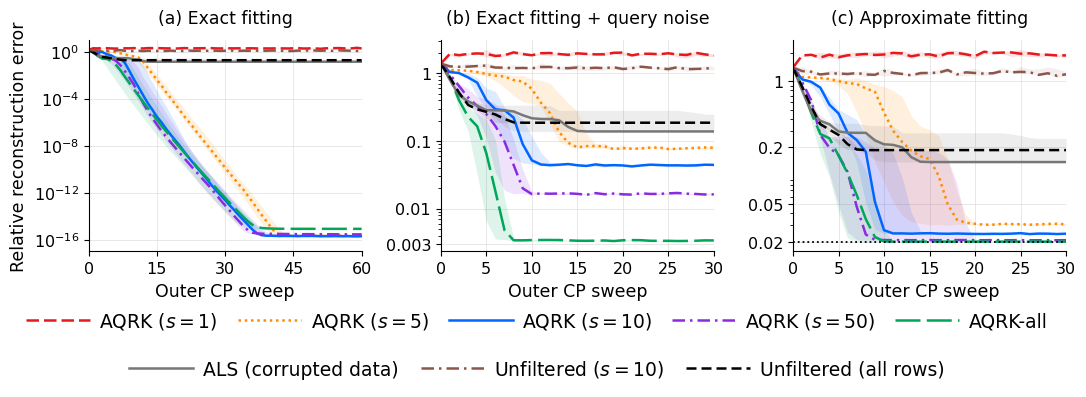

In [8]:
from plot_cp import plot_cp

figure = plot_cp(figure_run / "filtered", Path("generated_figures/cp30_2pct_full10"),
                 unfiltered_run=figure_run / "unfiltered",
                 unfiltered_s10_run=figure_run / "unfiltered")
plt.show()
